In [3]:
#link  https://www.youtube.com/redirect?event=video_description&redir_token=QUFFLUhqa2ZlQUMyOHNoOFVqV25QMGx2VWhZOGxETkRSUXxBQ3Jtc0tub0xmUHhNS1BLc2xfcy1QOHVWZ1pMcFk0SnA2a1ZtNG1HNnFzU25oLWw0cGdjQTZYbDFCSzh2LWlfa2NJZWJ6QkZMZzByajlKcDNwTnY3U0JPT2hWNWRHb1ZMRDRzX2JiTXpZMDZpWVZ1bi1ybzhscw&q=https%3A%2F%2Fwww.kaggle.com%2Fdatasets%2Faiaiaidavid%2Fthe-big-dataset-of-ultra-marathon-running%2Fdiscussion%2F420633&v=4sZFkPw87ng


In [4]:
import pandas as pd
import seaborn as sns

In [5]:
df =   pd.read_csv('D:\Documents\Projects\TWO_CENTURIES_OF_UM_RACES.csv')

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\user\AppData\Local\Temp\ipykernel_4496\323540912.py:1: SyntaxWarning: invalid escape sequence '\D'
  df =   pd.read_csv('D:\Documents\Projects\TWO_CENTURIES_OF_UM_RACES.csv')
C:\Users\user\AppData\Local\Temp\ipykernel_4496\323540912.py:1: DtypeWarning: Columns (11) have mixed types. Specify dtype option on import or set low_memory=False.
  df =   pd.read_csv('D:\Documents\Projects\TWO_CENTURIES_OF_UM_RACES.csv')


In [6]:
df.head()

,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete club,Athlete country,Athlete year of birth,Athlete gender,Athlete age category,Athlete average speed,Athlete ID
0,2018,06.01.2018,Selva Costera (CHI),50km,22,4:51:39 h,Tnfrc,CHI,1978.0,M,M35,10.286,0
1,2018,06.01.2018,Selva Costera (CHI),50km,22,5:15:45 h,Roberto Echeverría,CHI,1981.0,M,M35,9.501,1
2,2018,06.01.2018,Selva Costera (CHI),50km,22,5:16:44 h,Puro Trail Osorno,CHI,1987.0,M,M23,9.472,2
3,2018,06.01.2018,Selva Costera (CHI),50km,22,5:34:13 h,Columbia,ARG,1976.0,M,M40,8.976,3
4,2018,06.01.2018,Selva Costera (CHI),50km,22,5:54:14 h,Baguales Trail,CHI,1992.0,M,M23,8.469,4


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7461195 entries, 0 to 7461194
Data columns (total 13 columns):
 #   Column                     Dtype  
---  ------                     -----  
 0   Year of event              int64  
 1   Event dates                object 
 2   Event name                 object 
 3   Event distance/length      object 
 4   Event number of finishers  int64  
 5   Athlete performance        object 
 6   Athlete club               object 
 7   Athlete country            object 
 8   Athlete year of birth      float64
 9   Athlete gender             object 
 10  Athlete age category       object 
 11  Athlete average speed      object 
 12  Athlete ID                 int64  
dtypes: float64(1), int64(3), object(9)
memory usage: 740.0+ MB


In [8]:
#clean up data
#show only USA races, 50km  or 50m, 2020
#step 1 show 50km or 50mi

In [11]:
#test for data misrepresentation

df['Event distance/length'].unique()

array(['50km', '6h', '63.9km', ..., '2925.7mi/64Etappen',
       '355km/5Etappen', '2906.1mi/64Etappen'], dtype=object)

In [28]:
#step 1 show 50km or 50mi
distance_year = (df['Event distance/length'].isin(['50km', '50mi'])) & (df['Year of event']== 2020)

In [25]:
df[df['Event name'] == 'Everglades 50 Mile Ultra Run (USA)']['Event name'].str.split('(').str[1].str.split(')').str[0].head()

51923    USA
51924    USA
51925    USA
51926    USA
51927    USA
Name: Event name, dtype: object

In [29]:
country = df['Event name'].str.split('(').str[1].str.split(')').str[0] == 'USA'

In [32]:
#combine the filters to get races that are 50km or 50mi, in the USA, and in 2020
df2 = df[distance_year & country]

In [34]:
df2.shape

(26090, 13)

In [36]:
#removing (USA) from the event name
df2['Event name'] = df2['Event name'].str.replace('(USA)', '')

C:\Users\user\AppData\Local\Temp\ipykernel_4496\1803189074.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['Event name'] = df2['Event name'].str.replace('(USA)', '')


In [37]:
df2.head()

,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete club,Athlete country,Athlete year of birth,Athlete gender,Athlete age category,Athlete average speed,Athlete ID
2539945,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,3:17:55 h,"*Normandy Park, WA",USA,1991.0,M,M23,15.158,71287
2539946,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:02:32 h,"*Gold Bar, WA",USA,1981.0,M,M35,12.369,629508
2539947,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:07:57 h,"*Vashon, WA",USA,1999.0,M,MU23,12.099,64838
2539948,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:22:02 h,"*Gig Harbor, WA",USA,1983.0,M,M35,11.449,704450
2539949,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:27:34 h,"*Bainbridge Island, WA",USA,1977.0,M,M40,11.212,810281


In [38]:
#clean athlete age
df2['Athlete age'] = df2['Year of event'] - df2['Athlete year of birth']

C:\Users\user\AppData\Local\Temp\ipykernel_4496\1625483000.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['Athlete age'] = df2['Year of event'] - df2['Athlete year of birth']


In [43]:
#remove h from athlete performance
df2['Athlete performance'] = df2['Athlete performance'].str.replace('h', '').str.strip()
df2.head()

C:\Users\user\AppData\Local\Temp\ipykernel_4496\1993852328.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['Athlete performance'] = df2['Athlete performance'].str.replace('h', '').str.strip()


,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete club,Athlete country,Athlete year of birth,Athlete gender,Athlete age category,Athlete average speed,Athlete ID,Athlete age
2539945,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,3:17:55,"*Normandy Park, WA",USA,1991.0,M,M23,15.158,71287,29.0
2539946,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:02:32,"*Gold Bar, WA",USA,1981.0,M,M35,12.369,629508,39.0
2539947,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:07:57,"*Vashon, WA",USA,1999.0,M,MU23,12.099,64838,21.0
2539948,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:22:02,"*Gig Harbor, WA",USA,1983.0,M,M35,11.449,704450,37.0
2539949,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:27:34,"*Bainbridge Island, WA",USA,1977.0,M,M40,11.212,810281,43.0


In [ ]:
#drop columns: athlete clib, country, year of birth, age category
df2 = df2.drop(columns=['Athlete club', 'Athlete country', 'Athlete year of birth', 'Athlete age category'])


KeyError: "['Athlete club', 'Athlete country', 'Athlete year of birth', 'Athlete age category'] not found in axis"

In [49]:
df2.head()

,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete gender,Athlete average speed,Athlete ID,Athlete age
2539945,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,3:17:55,M,15.158,71287,29.0
2539946,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:02:32,M,12.369,629508,39.0
2539947,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:07:57,M,12.099,64838,21.0
2539948,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:22:02,M,11.449,704450,37.0
2539949,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:27:34,M,11.212,810281,43.0


In [54]:
df2.isna().sum()
df2 = df2.dropna()
df2.isna().sum()

Year of event                0
Event dates                  0
Event name                   0
Event distance/length        0
Event number of finishers    0
Athlete performance          0
Athlete gender               0
Athlete average speed        0
Athlete ID                   0
Athlete age                  0
dtype: int64

In [56]:
#checking for duplicates
df2[df2.duplicated() == True]

,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete gender,Athlete average speed,Athlete ID,Athlete age


In [58]:
#reset  index
df2 = df2.reset_index(drop = True)
df2.head()

,Year of event,Event dates,Event name,Event distance/length,Event number of finishers,Athlete performance,Athlete gender,Athlete average speed,Athlete ID,Athlete age
0,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,3:17:55,M,15.158,71287,29.0
1,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:02:32,M,12.369,629508,39.0
2,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:07:57,M,12.099,64838,21.0
3,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:22:02,M,11.449,704450,37.0
4,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:27:34,M,11.212,810281,43.0


In [59]:
df2.dtypes

Year of event                  int64
Event dates                   object
Event name                    object
Event distance/length         object
Event number of finishers      int64
Athlete performance           object
Athlete gender                object
Athlete average speed         object
Athlete ID                     int64
Athlete age                  float64
dtype: object

In [61]:
df2['Athlete age'] = df2['Athlete age'].astype(int)
df2['Athlete average speed'] = df2['Athlete average speed'].astype(float)

In [62]:
#rename columns
df2 = df2.rename(columns={'Year of event':'year',
'Event dates':'race_date',
'Event name':'race_name',
'Event distance/length': 'race_length',
'Event number of finishers':'race_no_of_finishers',
'Athlete performance':'athlete_performance',
'Athlete gender':'athlete_gender',
'Athlete average speed':'athlete_average_speed',
'Athlete ID':'athlete_id',
'Athlete age':'athlete_age'
})

In [63]:
df2.head()

,year,race_date,race_name,race_length,race_no_of_finishers,athlete_performance,athlete_gender,athlete_average_speed,athlete_id,athlete_age
0,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,3:17:55,M,15.158,71287,29
1,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:02:32,M,12.369,629508,39
2,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:07:57,M,12.099,64838,21
3,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:22:02,M,11.449,704450,37
4,2020,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,4:27:34,M,11.212,810281,43


In [67]:
#reorder columns
df3= df2[['race_date', 'race_name','race_length', 'race_no_of_finishers', 'athlete_id', 'athlete_gender', 'athlete_age', 'athlete_performance','athlete_average_speed']]

In [68]:
df3.head()

,race_date,race_name,race_length,race_no_of_finishers,athlete_id,athlete_gender,athlete_age,athlete_performance,athlete_average_speed
0,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,71287,M,29,3:17:55,15.158
1,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,629508,M,39,4:02:32,12.369
2,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,64838,M,21,4:07:57,12.099
3,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,704450,M,37,4:22:02,11.449
4,02.02.2020,West Seattle Beach Run - Winter Edition,50km,20,810281,M,43,4:27:34,11.212


<Axes: xlabel='race_length', ylabel='Count'>

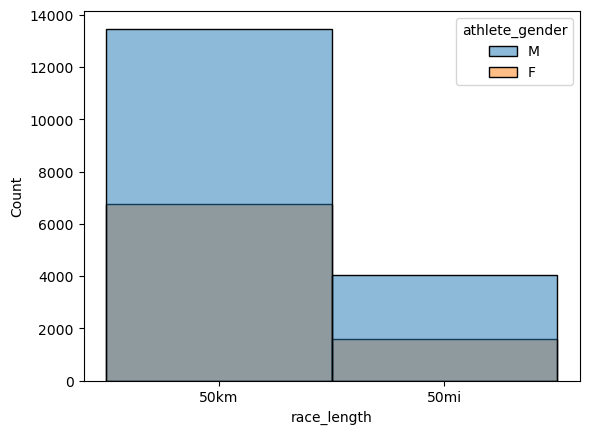

In [75]:
#charts and graphs
sns.histplot(df3, x = 'race_length', hue = 'athlete_gender')

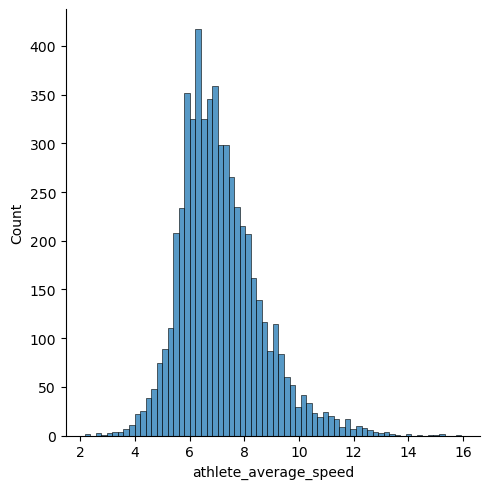

In [78]:
sns.displot(df3[df3['race_length']=='50mi']['athlete_average_speed'])

<Axes: xlabel='race_length', ylabel='athlete_average_speed'>

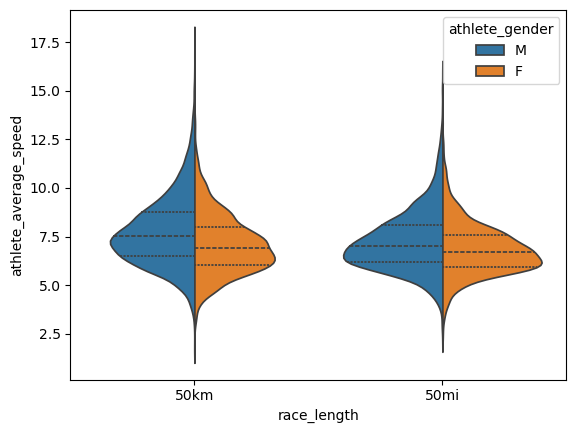

In [81]:
sns.violinplot(df3, x= 'race_length', y= 'athlete_average_speed', hue='athlete_gender',  split=True, inner = 'quart')

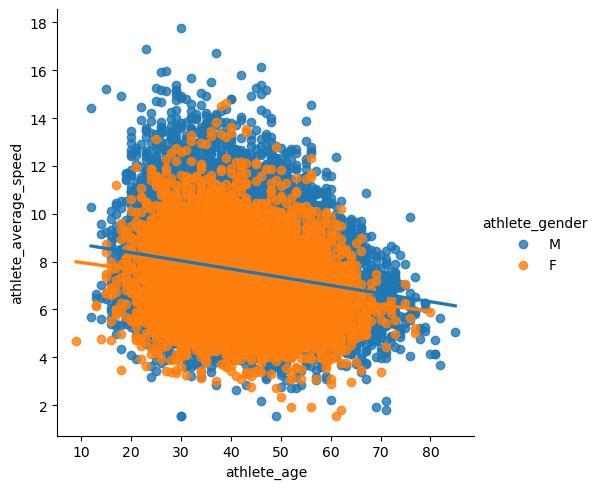

In [83]:
sns.lmplot(df3, x = 'athlete_age', y='athlete_average_speed', hue='athlete_gender' )

In [85]:
df3.columns

Index(['race_date', 'race_name', 'race_length', 'race_no_of_finishers',
       'athlete_id', 'athlete_gender', 'athlete_age', 'athlete_performance',
       'athlete_average_speed'],
      dtype='object')

In [ ]:
#Questions to answer with this dataset:
#difference in speed in 50km and 50mi male to female
#Age group performance in 50mi races with at least 20 races experience
#Seasonal performance

In [86]:
#difference in speed in 50km and 50mi male to female
df3.groupby(['race_length', 'athlete_gender'])['athlete_average_speed'].mean()

race_length  athlete_gender
50km         F                 7.083011
             M                 7.738985
50mi         F                 6.834371
             M                 7.257633
Name: athlete_average_speed, dtype: float64

In [93]:
#Age group performance in 50mi races with at least 10 races
df3.query('race_length == "50mi"').groupby('athlete_age')['athlete_average_speed'].agg(['mean', 'count']).query('count> 9').sort_values(by='mean', ascending=False)

,mean,count
athlete_age,,
29,7.902252,135
23,7.779800,55
28,7.575252,107
30,7.569204,157
25,7.540923,91
19,7.506133,15
31,7.451638,138
38,7.430022,231
35,7.422359,195


In [ ]:
#Seasonal performance
#spring = 3-5
#summer = 6-8
#autumn = 9-11
#winter = 12-2

In [97]:
df3['race_month'] = df3['race_date'].str.split('.').str[1].astype(int)


In [100]:
df3['race_season'] = df3['race_month'].apply(lambda x: 'spring' if x in [3,4,5] else('summer' if x in [6,7,8] else ('autumn' if x in [9,10,11] else 'winter')))

In [101]:
df3.groupby('race_season')['athlete_average_speed'].agg(['mean', 'count']).sort_values(by= 'mean', ascending = False)

,mean,count
race_season,,
spring,7.684430,3294
winter,7.518187,11595
autumn,7.406619,8315
summer,6.869336,2653
